# Pruebas y validación del detector de cascos · Proyecto Integrador
**Desarrollo de Soluciones Inteligentes · UBO · 2026 S2 · Hito 30-10: validación y bitácora de pruebas** (actividad formativa; apoya la revisión del 06-11 y el prototipo del 13-11)

Este notebook sigue la estructura de la Clase 11 (Palmer Penguins), pero con **el detector de casco de seguridad del equipo** (modelo Roboflow *Hard Hats v6*, el mismo del Taller 03). No entrena nada: valida el prototipo.

**Pregunta conductora:** ¿qué evidencia permite sostener que nuestro prototipo funciona y cuáles son sus límites?

| Sección | Qué se hace | Evidencia |
|---|---|---|
| 1–2 | Datos con trazabilidad, contrato de entrada y protocolo | Tabla de contrato, SHA-256 del dataset |
| 3 | Desempeño real: umbral elegido en *valid*, evaluación en *test* | Precisión, recall, F1, alerta por imagen |
| 4 | Análisis de errores | Galerías de FN y FP |
| 5–6 | App v1 (con fallas deliberadas) y app v2 (con validación) | Respuestas de ambas |
| 7 | Casos de prueba definidos **antes** de ejecutar | Bitácora acumulativa v1/v2 |
| 8–9 | Integración, robustez (poca luz, baja resolución) y límites por tamaño | Tablas |
| 10 | Mejoras priorizadas y pruebas manuales del equipo | Plantillas para completar |
| 11 | Excel de la bitácora, ZIP de evidencia y PDF | Archivos para entregar |

**Antes de ejecutar:** descarga el dataset en formato YOLO (Universe → *Download Dataset* → zip), súbelo a Drive y pon la ruta en `DATASET_ZIP`. La API key de Roboflow se pide de forma segura; no la pegues en el notebook. Ejecuta con *Entorno de ejecución → Ejecutar todas* (no necesita GPU).

**Consumo de créditos:** la evaluación consulta cerca de 350 imágenes una sola vez (con caché en archivos `.json`), y las pruebas de la suite, integración y robustez agregan unas 80 consultas. Si vuelves a ejecutar, no se repiten las consultas de la evaluación.

## Configuración (completar lo que dice COMPLETAR)

In [1]:
EQUIPO = "AMIR"
PARALELO = "D01"
INTEGRANTES = ["Antonia Moya, Isidora Ramos"]

MODEL_ID = "hard-hats-fhbh5/6"
API_URL = "https://serverless.roboflow.com"
URL_DATASET = "https://universe.roboflow.com/roboflow-universe-projects/hard-hats-fhbh5/dataset/6"
VERSION_MODELO = "roboflow_" + MODEL_ID.replace("/", "_v")
VERSION_APP_V1, VERSION_APP_V2 = "v1_sin_validacion", "v2_validada"

DATASET_ZIP = "/content/drive/MyDrive/AMIR/DATASET_ZIP/Hard Hats.v6-resized640_noaugmentation-rf-detr.yolo26.zip"
USAR_DRIVE = True                   # True: monta Google Drive para leer el zip

N_AJUSTE = 150        # imágenes de la partición valid para elegir el umbral
N_FINAL = 200         # imágenes de la partición test para la evaluación final
N_CONSISTENCIA = 5    # imágenes de test para comprobar que la app v2 conserva la salida del modelo
N_ROBUSTEZ = 30       # imágenes de test con 'sin casco' real para las pruebas de poca luz y baja resolución
SEED = 42
IOU_MIN = 0.5         # una detección acierta si su IoU con la caja real es >= 0,5
CONF_MIN = 0.10       # se consulta al modelo con umbral bajo UNA vez y luego se barre el umbral sin más llamadas
UMBRAL_ELEGIDO = None # None = se elige solo (máximo F1 de 'sin casco' en valid). O fija un número entre 0 y 1.

# Contrato de entrada de la aplicación
EXT_OK = {".jpg", ".jpeg", ".png"}
MAX_MB = 10           # tamaño máximo del archivo
LADO_MIN = 32         # menos de esto (px) se rechaza
LADO_ADVERTENCIA = 200  # menos de esto (px) se acepta con advertencia

USO_IA = ("Herramienta: Claude (Anthropic). Aporte: estructura del notebook de validación, código de pruebas y borrador de los textos de análisis a partir de las salidas de la ejecución. "
          "Verificación: las cifras y las figuras provienen de la ejecución del equipo en Colab con su dataset y su API key de Roboflow; los textos fueron revisados por el equipo contra las tablas y las galerías de errores.")

In [2]:
import os, re, io, json, csv, copy, numbers, hashlib, platform, sys, zipfile, random, getpass, warnings, tempfile
from pathlib import Path
from datetime import datetime, timezone
from collections import Counter
from importlib.metadata import version, PackageNotFoundError
import numpy as np, pandas as pd
from PIL import Image, ImageDraw, ImageOps, ImageEnhance
import matplotlib.pyplot as plt
from IPython.display import display, FileLink
warnings.filterwarnings("ignore")
try:
    from inference_sdk import InferenceHTTPClient, InferenceConfiguration
except ImportError:
    get_ipython().run_line_magic("pip", "install -q inference-sdk reportlab")
    from inference_sdk import InferenceHTTPClient, InferenceConfiguration

DIRECTORIO = Path("evidencia_validacion"); DIRECTORIO.mkdir(exist_ok=True)

def _v(p):
    try: return version(p)
    except PackageNotFoundError: return "no instalado"
ENTORNO = {"python": platform.python_version(), **{p: _v(p) for p in ["numpy", "pandas", "matplotlib", "pillow", "inference-sdk"]}}
display(pd.Series(ENTORNO, name="versión").to_frame())

if USAR_DRIVE and not os.path.exists(DATASET_ZIP):
    try:
        from google.colab import drive
        drive.mount("/content/drive")
    except Exception as e:
        print("No se pudo montar Drive:", e)
assert os.path.exists(DATASET_ZIP), f"No encuentro el zip en {DATASET_ZIP}. Revisa DATASET_ZIP."

def obtener_api_key():
    k = os.environ.get("ROBOFLOW_API_KEY")
    if not k:
        try:
            from google.colab import userdata
            k = userdata.get("ROBOFLOW_API_KEY")
        except Exception:
            k = None
    return k or getpass.getpass("API key de Roboflow (no se muestra): ")

API_KEY = obtener_api_key()
CLIENT = InferenceHTTPClient(api_url=API_URL, api_key=API_KEY)
CLIENT.configure(InferenceConfiguration(confidence_threshold=CONF_MIN))

def _limpiar(msg):
    msg = re.sub(r"(api_key=)[^&\s'\"]+", r"\1***", str(msg)).replace(API_KEY, "***")
    return msg if len(msg) <= 300 else msg[:300] + " …"
print("Listo. Modelo:", MODEL_ID, "| versión registrada:", VERSION_MODELO)

,versión
python,3.13.18
numpy,2.1.3
pandas,2.2.3
matplotlib,3.10.0
pillow,12.3.0
inference-sdk,1.8.4


API key de Roboflow (no se muestra): ··········
Listo. Modelo: hard-hats-fhbh5/6 | versión registrada: roboflow_hard-hats-fhbh5_v6


## 1. Datos y trazabilidad
Se usa el dataset **Hard Hats v6** (Roboflow Universe Projects, licencia **CC BY 4.0**): <https://universe.roboflow.com/roboflow-universe-projects/hard-hats-fhbh5/dataset/6>. Las etiquetas reales vienen del zip descargado (formato YOLO: clase, centro y tamaño normalizados) y se mapean a dos categorías: **casco** y **sin casco**.

Se registra la huella **SHA-256** del zip para que otra persona pueda comprobar que usó el mismo archivo. **Ojo con la privacidad:** las fotos del dataset incluyen personas con el rostro identificable; las galerías de errores las muestran, así que no las publiquen fuera del curso.

In [3]:
CATS = ["casco", "sin_casco"]
NOMBRE = {"casco": "Casco", "sin_casco": "Sin casco"}

def categoria(nombre):
    n = " ".join(re.sub(r"[^a-z0-9]+", " ", str(nombre).lower()).split())
    if re.search(r"\b(no|sin|without)\b.*(helmet|hardhat|hard hat|casco)|nohelmet|nohardhat", n):
        return "sin_casco"
    if re.search(r"helmet|hardhat|hard hat|casco", n):
        return "casco"
    return "otra"

def iou(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0])); iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    u = (a[2]-a[0])*(a[3]-a[1]) + (b[2]-b[0])*(b[3]-b[1]) - inter
    return inter / u if u > 0 else 0.0

def sha256_archivo(ruta):
    h = hashlib.sha256()
    with open(ruta, "rb") as f:
        for bloque in iter(lambda: f.read(1 << 20), b""): h.update(bloque)
    return h.hexdigest()
SHA256_ZIP = sha256_archivo(DATASET_ZIP)

ZIP = zipfile.ZipFile(DATASET_ZIP)
NOMBRES_ZIP = ZIP.namelist()
import yaml
_yml = [n for n in NOMBRES_ZIP if n.endswith("data.yaml")][0]
_names = yaml.safe_load(ZIP.read(_yml))["names"]
CLASES_DATASET = [_names[k] for k in sorted(_names)] if isinstance(_names, dict) else list(_names)
MAPA_CLASES = {i: categoria(n) for i, n in enumerate(CLASES_DATASET)}

def listar_split(split):
    pats = {"valid": ["valid", "val"], "test": ["test"]}[split]
    for p in pats:
        imgs = sorted(n for n in NOMBRES_ZIP if re.search(rf"(^|/){p}/images/[^/]+\.(jpg|jpeg|png)$", n, re.I))
        if imgs:
            return imgs
    return []

def cargar_gt(zname, W, H):
    base, _, resto = zname.rpartition("/images/")
    lab = f"{base}/labels/{resto.rsplit('.', 1)[0]}.txt" if base else f"labels/{resto.rsplit('.', 1)[0]}.txt"
    if lab not in NOMBRES_ZIP:
        return []
    out = []
    for linea in ZIP.read(lab).decode().splitlines():
        p = linea.split()
        if len(p) < 5: continue
        c = int(float(p[0])); v = list(map(float, p[1:]))
        if len(v) == 4:
            cx, cy, w, h = v; x1, y1, x2, y2 = (cx-w/2)*W, (cy-h/2)*H, (cx+w/2)*W, (cy+h/2)*H
        else:                                   # polígono: se toma su caja envolvente
            xs, ys = v[0::2], v[1::2]; x1, y1, x2, y2 = min(xs)*W, min(ys)*H, max(xs)*W, max(ys)*H
        cat = MAPA_CLASES.get(c, "otra")
        if cat in CATS:
            out.append({"cat": cat, "box": (x1, y1, x2, y2), "area": ((x2-x1)*(y2-y1))/(W*H)})
    return out

def tomar_muestra(split, n, carpeta):
    todos = listar_split(split)
    assert todos, f"No encontré imágenes de la partición '{split}' en el zip."
    elegidos = sorted(random.Random(SEED).sample(todos, min(n, len(todos))))
    os.makedirs(carpeta, exist_ok=True); muestra = []
    for z in elegidos:
        ruta = os.path.join(carpeta, os.path.basename(z))
        with open(ruta, "wb") as f: f.write(ZIP.read(z))
        W, H = Image.open(ruta).size
        muestra.append({"id": os.path.basename(z), "path": ruta, "W": W, "H": H, "gt": cargar_gt(z, W, H)})
    return muestra, len(todos)

MUESTRA_AJ, TOTAL_AJ = tomar_muestra("valid", N_AJUSTE, "/content/val_valid" if os.path.isdir("/content") else "val_valid")
MUESTRA_FIN, TOTAL_FIN = tomar_muestra("test", N_FINAL, "/content/val_test" if os.path.isdir("/content") else "val_test")

def resumen_muestra(m):
    c = Counter(b["cat"] for im in m for b in im["gt"])
    return len(m), c["casco"], c["sin_casco"], sum(1 for im in m if any(b["cat"] == "sin_casco" for b in im["gt"]))

tabla_datos = pd.DataFrame(
    [["valid (ajuste de umbral)", TOTAL_AJ, *resumen_muestra(MUESTRA_AJ)],
     ["test (evaluación final)", TOTAL_FIN, *resumen_muestra(MUESTRA_FIN)]],
    columns=["partición", "imágenes en el dataset", "imágenes en la muestra", "cajas 'casco'", "cajas 'sin casco'", "imágenes con 'sin casco'"])
print("Clases del dataset y su categoría:", {n: MAPA_CLASES[i] for i, n in enumerate(CLASES_DATASET)})
print("SHA-256 del zip:", SHA256_ZIP)
tabla_datos

Clases del dataset y su categoría: {'Hardhat': 'casco', 'NO-Hardhat': 'sin_casco'}
SHA-256 del zip: d105ed599f42c48b9198dbc93b02a80847c14e2555b4769398778dc92fe7c6f4


,partición,imágenes en el dataset,imágenes en la muestra,cajas 'casco',cajas 'sin casco',imágenes con 'sin casco'
0,valid (ajuste de umbral),3962,150,315,97,34
1,test (evaluación final),2001,200,402,128,40


### Contrato de la aplicación
La aplicación recibe **una imagen y, opcionalmente, un umbral de confianza**, y devuelve si hay que **alertar** (hay al menos una persona sin casco) junto con las detecciones. Antes de llamar al modelo, la versión corregida (v2) comprueba el contrato; la versión defectuosa (v1) no comprueba nada.

Que el modelo responda no significa que la respuesta sea correcta: la corrección se mide contra las etiquetas reales (sección 3) y el contrato se comprueba con casos de prueba (sección 7).

In [4]:
UMBRAL_PREVIO = 0.5   # umbral por defecto de la app si el usuario no entrega uno; se reemplaza por el elegido en valid (sección 3)
CONTRATO = pd.DataFrame([
    {"campo": "imagen", "tipo": "ruta a un archivo .jpg, .jpeg o .png", "obligatorio": True,
     "regla": f"existe, no vacío, ≤ {MAX_MB} MB, legible como imagen, lado menor ≥ {LADO_MIN} px (advertencia bajo {LADO_ADVERTENCIA} px)"},
    {"campo": "umbral", "tipo": "número real, no booleano", "obligatorio": False,
     "regla": "finito y estrictamente entre 0 y 1; si falta, se usa el umbral elegido en valid"},
    {"campo": "(salida)", "tipo": "diccionario", "obligatorio": True,
     "regla": "estado ('ok', 'error_validacion' o 'error_servicio'), alerta (bool), detecciones (clase, confianza, caja), advertencias, versiones"}])
CONTRATO

,campo,tipo,obligatorio,regla
0,imagen,"ruta a un archivo .jpg, .jpeg o .png",True,"existe, no vacío, ≤ 10 MB, legible como imagen..."
1,umbral,"número real, no booleano",False,"finito y estrictamente entre 0 y 1; si falta, ..."
2,(salida),diccionario,True,"estado ('ok', 'error_validacion' o 'error_serv..."


## 2. Protocolo antes de evaluar
- **Muestra reproducible:** se toman al azar (semilla fija) imágenes de las particiones `valid` y `test` del dataset, con sus etiquetas reales. Una detección es acierto si su clase coincide y su **IoU ≥ 0,5** con una caja real aún no usada.
- **El umbral se elige en `valid`** (máximo F1 de «sin casco») y se **evalúa una sola vez en `test`**. Si luego se cambia algo mirando el resultado de test, deja de ser una prueba final independiente.
- Si el modelo alojado se entrenó con este mismo dataset, el resultado puede ser más optimista que en obras nuevas.

### Criterios fijados
- Entradas inválidas: respuesta controlada que identifique el campo y evite llamar al modelo.
- Integración: la app v2 debe entregar las mismas detecciones que la consulta directa al modelo.
- Imagen de baja resolución o sin detecciones: respuesta con advertencia explícita.
- Desempeño: informar precisión, recall y F1 por clase y la alerta por imagen. **No inventamos un umbral universal de aceptación**; la decisión de si alcanza para el uso real la toma el equipo y la justifica en la bitácora.

## 3. Desempeño real del modelo
**Precisión:** de las cajas que el modelo dibujó, cuántas eran correctas. **Recall:** de los objetos reales, cuántos encontró. **F1:** equilibrio entre ambos. Además se mide la pregunta que le importa al usuario, a nivel de imagen: **¿hay alguien sin casco? (alerta sí/no)**.

Se consulta el modelo una vez por imagen y se guarda la respuesta cruda en `pred_valid.json` y `pred_test.json`: si vuelves a ejecutar, no se repiten las llamadas.

In [5]:
def parsear(r):
    L = []
    for p in r.get("predictions", []):
        x, y, w, h = p["x"], p["y"], p["width"], p["height"]
        L.append({"cat": categoria(p["class"]), "clase": p["class"], "conf": float(p["confidence"]),
                  "box": (x-w/2, y-h/2, x+w/2, y+h/2)})
    return L

def consultar_modelo(origen):
    """Una consulta al modelo (ruta de archivo o imagen PIL). Devuelve todas las detecciones con confianza >= CONF_MIN."""
    return parsear(CLIENT.infer(origen, model_id=MODEL_ID))

def predecir(muestra, nombre_cache):
    cache = {}
    if os.path.exists(nombre_cache):
        c = json.load(open(nombre_cache))
        if c.get("model_id") == MODEL_ID and c.get("seed") == SEED:
            cache = c["preds"]
    seguidos = 0
    for i, m in enumerate(muestra, 1):
        if m["id"] in cache: continue
        try:
            L = consultar_modelo(m["path"]); seguidos = 0
        except Exception as e:
            seguidos += 1
            print("Error de servicio en", m["id"], "->", _limpiar(f"{type(e).__name__}: {e}"))
            if seguidos >= 5:
                raise RuntimeError("5 errores seguidos: se detiene. Revisa MODEL_ID, la API key o tus créditos.") from None
            continue
        cache[m["id"]] = L
        if i % 25 == 0: print(f"  {i}/{len(muestra)} imágenes")
    json.dump({"model_id": MODEL_ID, "seed": SEED, "preds": cache}, open(nombre_cache, "w"))
    faltan = [m["id"] for m in muestra if m["id"] not in cache]
    if faltan: print("OJO: sin respuesta para", len(faltan), "imágenes (se excluyen de la evaluación).")
    return cache

PRED_AJ = predecir(MUESTRA_AJ, "pred_valid.json")
PRED_FIN = predecir(MUESTRA_FIN, "pred_test.json")
MUESTRA_AJ = [m for m in MUESTRA_AJ if m["id"] in PRED_AJ]
MUESTRA_FIN = [m for m in MUESTRA_FIN if m["id"] in PRED_FIN]
print("Imágenes evaluables -> valid:", len(MUESTRA_AJ), "| test:", len(MUESTRA_FIN))

  25/150 imágenes
  50/150 imágenes
  75/150 imágenes
  100/150 imágenes
  125/150 imágenes
  150/150 imágenes
  25/200 imágenes
  50/200 imágenes
  75/200 imágenes
  100/200 imágenes
  125/200 imágenes
  150/200 imágenes
  175/200 imágenes
  200/200 imágenes
Imágenes evaluables -> valid: 150 | test: 200


Umbral elegido EN VALID: 0.3  (criterio: máximo F1 de 'sin casco')


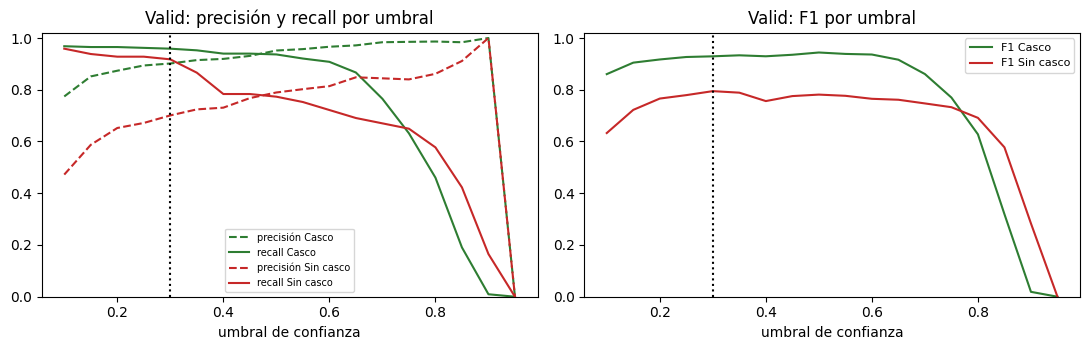

,umbral,P_casco,R_casco,F1_casco,P_sin_casco,R_sin_casco,F1_sin_casco,R_alerta,P_alerta
0,0.10,0.774,0.968,0.860,0.472,0.959,0.633,1.000,0.895
1,0.15,0.852,0.965,0.905,0.587,0.938,0.722,1.000,0.919
2,0.20,0.874,0.965,0.917,0.652,0.928,0.766,1.000,0.944
3,0.25,0.894,0.962,0.927,0.672,0.928,0.779,1.000,0.944
4,0.30,0.901,0.959,0.929,0.701,0.918,0.795,1.000,0.944
5,0.35,0.915,0.952,0.933,0.724,0.866,0.789,1.000,0.944
6,0.40,0.919,0.940,0.929,0.731,0.784,0.756,0.941,0.941
7,0.45,0.931,0.940,0.935,0.768,0.784,0.776,0.941,0.941
8,0.50,0.952,0.937,0.944,0.789,0.773,0.781,0.941,0.941
9,0.55,0.957,0.921,0.939,0.802,0.753,0.777,0.912,0.939


In [6]:
def prf(tp, fp, fn):
    p = tp/(tp+fp) if tp+fp else 0.0; r = tp/(tp+fn) if tp+fn else 0.0
    return p, r, (2*p*r/(p+r) if p+r else 0.0)

def evaluar(muestra, preds, thr):
    tot = {c: Counter() for c in CATS}; gts = []; errores = []; filas = []
    for m in muestra:
        P = [p for p in preds[m["id"]] if p["conf"] >= thr]
        for c in CATS:
            g = [b for b in m["gt"] if b["cat"] == c]
            p = sorted([b for b in P if b["cat"] == c], key=lambda b: -b["conf"]); usado = set()
            for pb in p:
                mejor, bi = 0.0, None
                for i, gb in enumerate(g):
                    if i in usado: continue
                    v = iou(pb["box"], gb["box"])
                    if v > mejor: mejor, bi = v, i
                if bi is not None and mejor >= IOU_MIN:
                    usado.add(bi); tot[c]["tp"] += 1
                else:
                    tot[c]["fp"] += 1; errores.append({"img": m["id"], "tipo": "FP", "cat": c, "conf": pb["conf"], "box": pb["box"]})
            for i, gb in enumerate(g):
                ok = i in usado
                if not ok:
                    tot[c]["fn"] += 1; errores.append({"img": m["id"], "tipo": "FN", "cat": c, "conf": None, "box": gb["box"]})
                gts.append({"cat": c, "ok": ok, "area": gb["area"]})
        filas.append((any(b["cat"] == "sin_casco" for b in m["gt"]), any(b["cat"] == "sin_casco" for b in P)))
    ia = Counter()
    for g, p in filas: ia[("TP" if p else "FN") if g else ("FP" if p else "TN")] += 1
    return {"tot": tot, "gts": gts, "errores": errores, "img": ia}

UMBRALES = [round(x, 2) for x in np.arange(0.10, 0.951, 0.05)]
filas = []
for t in UMBRALES:
    e = evaluar(MUESTRA_AJ, PRED_AJ, t)
    f = {"umbral": t}
    for c in CATS:
        p, r, f1 = prf(e["tot"][c]["tp"], e["tot"][c]["fp"], e["tot"][c]["fn"])
        f.update({f"P_{c}": p, f"R_{c}": r, f"F1_{c}": f1})
    ia = e["img"]; f["R_alerta"] = ia["TP"]/(ia["TP"]+ia["FN"]) if ia["TP"]+ia["FN"] else 0.0
    f["P_alerta"] = ia["TP"]/(ia["TP"]+ia["FP"]) if ia["TP"]+ia["FP"] else 0.0
    filas.append(f)
BARRIDO = pd.DataFrame(filas)
UMBRAL = UMBRAL_ELEGIDO if UMBRAL_ELEGIDO is not None else float(BARRIDO.loc[BARRIDO["F1_sin_casco"].idxmax(), "umbral"])
print(f"Umbral elegido EN VALID: {UMBRAL}  (criterio: máximo F1 de 'sin casco'" + ("" if UMBRAL_ELEGIDO is None else "; fijado a mano") + ")")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for c, col in zip(CATS, ["#2e7d32", "#c62828"]):
    ax[0].plot(BARRIDO["umbral"], BARRIDO[f"P_{c}"], "--", color=col, label=f"precisión {NOMBRE[c]}")
    ax[0].plot(BARRIDO["umbral"], BARRIDO[f"R_{c}"], "-", color=col, label=f"recall {NOMBRE[c]}")
ax[0].axvline(UMBRAL, color="k", ls=":"); ax[0].set_xlabel("umbral de confianza"); ax[0].set_ylim(0, 1.02)
ax[0].set_title("Valid: precisión y recall por umbral"); ax[0].legend(fontsize=7)
ax[1].plot(BARRIDO["umbral"], BARRIDO["F1_casco"], color="#2e7d32", label="F1 Casco")
ax[1].plot(BARRIDO["umbral"], BARRIDO["F1_sin_casco"], color="#c62828", label="F1 Sin casco")
ax[1].axvline(UMBRAL, color="k", ls=":"); ax[1].set_xlabel("umbral de confianza"); ax[1].set_ylim(0, 1.02)
ax[1].set_title("Valid: F1 por umbral"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(DIRECTORIO / "fig_barrido_umbral.png", dpi=150); plt.show()
BARRIDO.round(3)

In [7]:
# ===== EVALUACIÓN FINAL EN TEST (una vez, con el umbral ya elegido en valid) =====
FINAL = evaluar(MUESTRA_FIN, PRED_FIN, UMBRAL)
filas = []
for c in CATS:
    t = FINAL["tot"][c]; p, r, f1 = prf(t["tp"], t["fp"], t["fn"])
    filas.append([NOMBRE[c], t["tp"], t["fp"], t["fn"], round(p, 3), round(r, 3), round(f1, 3)])
TABLA_FINAL = pd.DataFrame(filas, columns=["clase", "TP", "FP", "FN", "precisión", "recall", "F1"])
ia = FINAL["img"]
CONF_IMG = pd.DataFrame([[ia["TN"], ia["FP"]], [ia["FN"], ia["TP"]]],
                        index=["real: sin infractores", "real: hay 'sin casco'"], columns=["modelo: sin alerta", "modelo: ALERTA"])
print(f"Umbral {UMBRAL} · test: {len(MUESTRA_FIN)} imágenes · IoU ≥ {IOU_MIN}")
display(TABLA_FINAL); display(CONF_IMG)
print("Que no haya errores en una muestra no garantiza el desempeño fuera de ella; y si los hay, hay que mirarlos (sección 4).")

Umbral 0.3 · test: 200 imágenes · IoU ≥ 0.5


,clase,TP,FP,FN,precisión,recall,F1
0,Casco,375,44,27,0.895,0.933,0.914
1,Sin casco,125,13,3,0.906,0.977,0.940


,modelo: sin alerta,modelo: ALERTA
real: sin infractores,158,2
real: hay 'sin casco',0,40


Que no haya errores en una muestra no garantiza el desempeño fuera de ella; y si los hay, hay que mirarlos (sección 4).


## 4. Análisis de errores
Una detección puede tener buen formato y ser incorrecta. Galería de errores de **test**: **verde = caja real**, **rojo = detección del modelo** (con su confianza). Los **FN** son personas sin casco que el modelo no encontró (lo más grave para la seguridad); los **FP** son detecciones sin caja real.

'Sin casco' no detectados (FN): 3 · falsas alarmas (FP): 13
FN (persona sin casco que no se alertó)


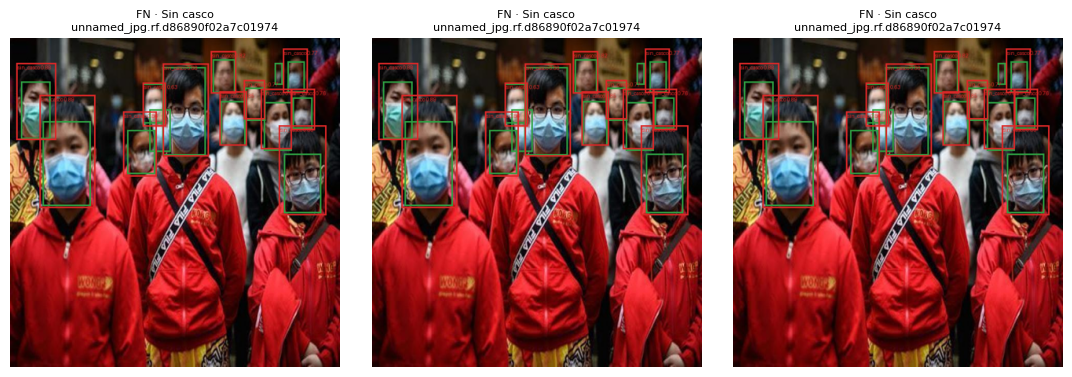

FP (falsas alarmas)


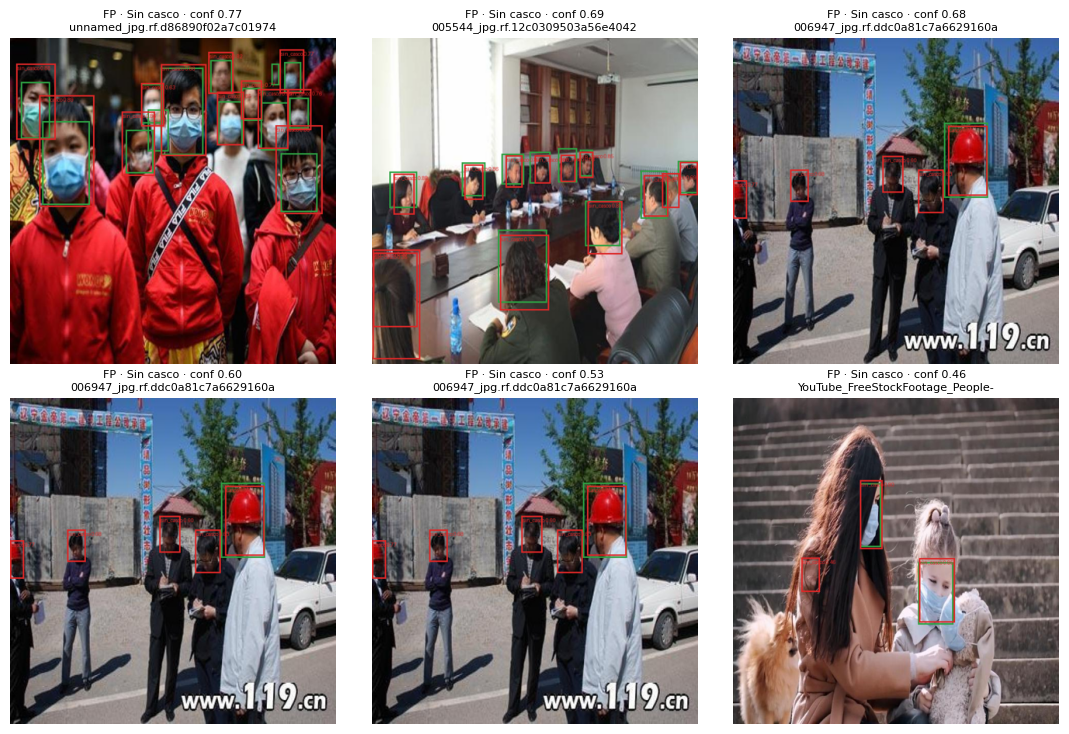

In [8]:
def dibujar_error(e, lado=420):
    m = next(x for x in MUESTRA_FIN if x["id"] == e["img"])
    im = ImageOps.exif_transpose(Image.open(m["path"])).convert("RGB"); d = ImageDraw.Draw(im)
    for b in m["gt"]: d.rectangle(b["box"], outline=(46, 160, 67), width=3)
    for p in PRED_FIN[m["id"]]:
        if p["conf"] >= UMBRAL: d.rectangle(p["box"], outline=(220, 40, 40), width=3); d.text((p["box"][0]+3, p["box"][1]+3), f"{p['cat']} {p['conf']:.2f}", fill=(220, 40, 40))
    im.thumbnail((lado, lado)); return im

def galeria(errores, n=6, archivo="fig_errores.png"):
    sel = sorted(errores, key=lambda e: -(e["conf"] or 0))[:n] if errores and errores[0]["tipo"] == "FP" else errores[:n]
    if not sel: print("Sin errores de este tipo."); return
    cols = 3; filas_ = (len(sel)+cols-1)//cols
    fig, ax = plt.subplots(filas_, cols, figsize=(11, 3.7*filas_)); ax = np.array(ax).reshape(-1)
    for a in ax: a.axis("off")
    for a, e in zip(ax, sel):
        a.imshow(dibujar_error(e)); a.set_title(f"{e['tipo']} · {NOMBRE[e['cat']]}" + (f" · conf {e['conf']:.2f}" if e['conf'] else "") + f"\n{e['img'][:32]}", fontsize=8)
    plt.tight_layout(); plt.savefig(DIRECTORIO / archivo, dpi=130); plt.show()

ERR_FN = [e for e in FINAL["errores"] if e["tipo"] == "FN" and e["cat"] == "sin_casco"]
ERR_FP = [e for e in FINAL["errores"] if e["tipo"] == "FP" and e["cat"] == "sin_casco"]
print(f"'Sin casco' no detectados (FN): {len(ERR_FN)} · falsas alarmas (FP): {len(ERR_FP)}")
print("FN (persona sin casco que no se alertó)"); galeria(ERR_FN, archivo="fig_errores_fn.png")
print("FP (falsas alarmas)"); galeria(ERR_FP, archivo="fig_errores_fp.png")
pd.DataFrame(FINAL["errores"]).to_csv(DIRECTORIO / "errores_test.csv", index=False)

In [9]:
# Análisis del equipo, escrito a partir de las tablas y las galerías de errores de esta ejecución.
ANALISIS_ERRORES = (
    "Falsos negativos de 'sin casco' (3 en test): los tres vienen de una sola imagen, un grupo de personas con mascarillas fotografiado de cerca, "
    "en una escena que no es de obra y con muchas cabezas pequeñas y muy juntas al fondo; en una imagen así hay varias cajas reales superpuestas, "
    "y alguna quedó sin una detección con IoU suficiente. A nivel de imagen no se perdió ninguna alerta (FN = 0 de 40). "
    "Falsas alarmas de 'sin casco' (13 en test): en la galería varias parecen etiquetas faltantes del dataset y no errores del modelo. "
    "En la foto de la calle, el modelo marca como 'sin casco' las cabezas de las personas de ropa oscura (confianza 0,53 a 0,68) y el dataset solo "
    "tiene caja para el hombre del casco rojo. En la reunión de oficina y en el grupo con mascarillas aparecen cajas rojas junto a cajas reales: "
    "probablemente son cajas desplazadas (IoU menor a 0,5) o duplicadas. Hay además una detección de confianza baja (0,46) que parece estar sobre un perro. "
    "Varias de las imágenes del conjunto de test no son de obra (oficina, mascarillas, fotos de stock), por lo que parte del error mide otra cosa que el uso real. "
    "Por tamaño, los cascos pequeños se detectan peor (recall 0,83 con 132 de 159) que los medianos y grandes (1,00).")
DECISION_UMBRAL = (
    "Se adoptó 0,3 como umbral por defecto de la app: es el que maximiza el F1 de 'sin casco' en valid (0,795; precisión 0,70 y recall 0,92). "
    "Para este uso es peor no alertar a una persona sin casco que dar una falsa alarma, porque la alerta la revisa una persona y un caso perdido no se ve. "
    "Con 0,3 el recall de alerta por imagen en valid es 1,00; con 0,5 baja a 0,94 y el recall de 'sin casco' a 0,77. "
    "El umbral se eligió en valid y no se cambió después de mirar test.")
LIMITACIONES = (
    f"La muestra es de {len(MUESTRA_AJ)} imágenes de valid y {len(MUESTRA_FIN)} de test (no el dataset completo), tomada al azar con semilla {SEED}; "
    "las métricas tienen incertidumbre (en test hay 128 cajas de 'sin casco' en 40 imágenes). "
    "El dataset es de terceros e incluye imágenes que no son de obra y personas con el rostro identificable; puede no representar las obras del contexto real. "
    "Faltan etiquetas en algunas imágenes (personas sin casco sin caja), lo que baja la precisión medida. "
    "Si el modelo alojado se entrenó con este mismo dataset, el resultado puede ser más optimista que en obras nuevas; "
    "además, 'sin casco' salió mejor en test (F1 0,94) que en valid (0,80), una diferencia que no se investigó. "
    "La prueba de integración exigió igualdad exacta y falló en 1 de 5 imágenes; no se identificó la causa. "
    "La robustez se probó solo con dos cambios (poca luz y baja resolución) sobre 30 imágenes. No se probó con video ni con cámaras reales.")
USO_IA = ("Herramienta: Claude (Anthropic). Aporte: estructura del notebook de validación, código de pruebas y borrador de los textos de análisis a partir de las salidas de la ejecución. "
          "Verificación: las cifras y las figuras provienen de la ejecución del equipo en Colab con su dataset y su API key de Roboflow; los textos fueron revisados por el equipo contra las tablas y las galerías de errores.")

## 5. Aplicación v1: fallas deliberadas
Esta primera versión llama al modelo **sin validar la solicitud**. La usamos para observar qué pasa con entradas inválidas: errores técnicos sin explicación, o respuestas «correctas» que en realidad son engañosas. **Es un ejemplo intencionalmente defectuoso.**

La respuesta indica si hay que alertar y entrega las detecciones, pero la confianza del modelo no demuestra que la predicción sea correcta.

In [10]:
def formatear(dets, umbral, advertencias, version_app):
    vis = sorted([d for d in dets if d["conf"] >= umbral], key=lambda d: -d["conf"])
    return {"estado": "ok",
            "alerta": any(d["cat"] == "sin_casco" for d in vis),
            "detecciones": [{"clase": d["clase"], "categoria": d["cat"], "confianza": round(d["conf"], 4),
                             "caja": [round(float(v), 1) for v in d["box"]]} for d in vis],
            "advertencias": list(advertencias), "version_app": version_app, "version_modelo": VERSION_MODELO}

def app_v1(solicitud):
    # Falla deliberada: no valida archivo, formato, tamaño ni umbral.
    dets = consultar_modelo(solicitud["imagen"])
    return formatear(dets, solicitud.get("umbral", UMBRAL_PREVIO), [], VERSION_APP_V1)

IMG_NORMAL = next((m for m in MUESTRA_FIN if any(b["cat"] == "sin_casco" for b in m["gt"])), MUESTRA_FIN[0])
print("Imagen de prueba normal:", IMG_NORMAL["id"])
display(app_v1({"imagen": IMG_NORMAL["path"], "umbral": UMBRAL}))

Imagen de prueba normal: 000081_jpg.rf.ce914c9c27979ac9bf729734053ade00.jpg


{'estado': 'ok',
 'alerta': True,
 'detecciones': [{'clase': 'Hardhat',
   'categoria': 'casco',
   'confianza': 0.8838,
   'caja': [468.0, 1.0, 584.0, 183.0]},
  {'clase': 'NO-Hardhat',
   'categoria': 'sin_casco',
   'confianza': 0.7576,
   'caja': [65.0, 75.0, 125.0, 188.0]},
  {'clase': 'NO-Hardhat',
   'categoria': 'sin_casco',
   'confianza': 0.7429,
   'caja': [283.0, 47.0, 356.0, 168.0]},
  {'clase': 'NO-Hardhat',
   'categoria': 'sin_casco',
   'confianza': 0.7257,
   'caja': [400.0, 65.0, 449.0, 152.0]},
  {'clase': 'NO-Hardhat',
   'categoria': 'sin_casco',
   'confianza': 0.7123,
   'caja': [253.0, 38.0, 301.0, 142.0]},
  {'clase': 'NO-Hardhat',
   'categoria': 'sin_casco',
   'confianza': 0.6983,
   'caja': [32.0, 66.0, 76.0, 153.0]},
  {'clase': 'NO-Hardhat',
   'categoria': 'sin_casco',
   'confianza': 0.6729,
   'caja': [441.0, 70.0, 472.0, 145.0]},
  {'clase': 'NO-Hardhat',
   'categoria': 'sin_casco',
   'confianza': 0.6484,
   'caja': [581.0, 75.0, 616.0, 140.0]},
  

## 6. Aplicación v2: validación y advertencias
La versión corregida **separa la validación del contrato de la consulta al modelo**: rechaza lo inválido con un mensaje que identifica el campo, avisa cuando la imagen es muy pequeña, corrige la orientación EXIF (fotos de celular giradas) y avisa cuando no hay detecciones, porque *sin detecciones* puede significar «no hay personas» o «el modelo no las vio»: una persona debe revisar.

El umbral por defecto pasa a ser el elegido en `valid`.

In [11]:
UMBRAL_DEFECTO = UMBRAL

def validar_entrada(solicitud):
    """Devuelve (imagen_para_el_modelo, umbral, errores, advertencias)."""
    errores_v, adv, img_modelo = [], [], None
    if not isinstance(solicitud, dict):
        return None, UMBRAL_DEFECTO, ["La solicitud debe ser un diccionario con los campos 'imagen' y 'umbral'."], []
    extras = set(solicitud) - {"imagen", "umbral"}
    if extras:
        errores_v.append("Campos no admitidos: " + ", ".join(sorted(map(str, extras))))
    # --- imagen
    if "imagen" not in solicitud:
        errores_v.append("imagen: campo obligatorio ausente.")
    elif not isinstance(solicitud["imagen"], (str, Path)):
        errores_v.append("imagen: se requiere la ruta de un archivo (texto).")
    else:
        ruta = Path(solicitud["imagen"])
        if not ruta.is_file():
            errores_v.append("imagen: el archivo no existe.")
        elif ruta.suffix.lower() not in EXT_OK:
            errores_v.append("imagen: formato no admitido (use .jpg, .jpeg o .png).")
        elif ruta.stat().st_size == 0:
            errores_v.append("imagen: el archivo está vacío.")
        elif ruta.stat().st_size > MAX_MB * 1024 * 1024:
            errores_v.append(f"imagen: supera el máximo de {MAX_MB} MB.")
        else:
            try:
                with Image.open(ruta) as im:
                    im.verify()
                with Image.open(ruta) as im:
                    im.load(); W, H = im.size; orient = im.getexif().get(274, 1)
                    if min(W, H) < LADO_MIN:
                        errores_v.append(f"imagen: demasiado pequeña ({W}x{H} px); el lado menor debe ser de al menos {LADO_MIN} px.")
                    else:
                        if min(W, H) < LADO_ADVERTENCIA:
                            adv.append(f"imagen: resolución baja ({W}x{H} px); los objetos pequeños pueden no detectarse.")
                        if orient not in (1, None):
                            img_modelo = ImageOps.exif_transpose(im).convert("RGB")
                            adv.append("imagen: orientación EXIF corregida antes de consultar el modelo.")
                        else:
                            img_modelo = str(ruta)
            except Exception:
                errores_v.append("imagen: el archivo no es una imagen legible (puede estar dañado).")
    # --- umbral
    umbral = UMBRAL_DEFECTO
    if "umbral" in solicitud:
        u = solicitud["umbral"]
        if isinstance(u, (bool, np.bool_)) or not isinstance(u, numbers.Real):
            errores_v.append("umbral: se requiere un número real, no texto ni booleanos.")
        elif not np.isfinite(float(u)):
            errores_v.append("umbral: se requiere un valor finito.")
        elif not (0 < float(u) < 1):
            errores_v.append("umbral: debe estar estrictamente entre 0 y 1.")
        else:
            umbral = float(u)
    return img_modelo, umbral, errores_v, adv

def app_v2(solicitud):
    img_modelo, umbral, fallas, adv = validar_entrada(solicitud)
    if fallas:
        return {"estado": "error_validacion", "errores": fallas, "advertencias": adv,
                "version_app": VERSION_APP_V2, "version_modelo": VERSION_MODELO}
    try:
        dets = consultar_modelo(img_modelo)
    except Exception as e:
        return {"estado": "error_servicio", "errores": ["No se pudo consultar el modelo: " + _limpiar(f"{type(e).__name__}: {e}")],
                "advertencias": adv, "version_app": VERSION_APP_V2, "version_modelo": VERSION_MODELO}
    r = formatear(dets, umbral, adv, VERSION_APP_V2)
    if not r["detecciones"]:
        r["advertencias"].append("Sin detecciones: puede no haber personas o el modelo no las vio; una persona debe revisar la imagen.")
    return r

display(app_v2({"imagen": IMG_NORMAL["path"]}))
display(app_v2({"imagen": IMG_NORMAL["path"], "umbral": 1.5}))

{'estado': 'ok',
 'alerta': True,
 'detecciones': [{'clase': 'Hardhat',
   'categoria': 'casco',
   'confianza': 0.8838,
   'caja': [468.0, 1.0, 584.0, 183.0]},
  {'clase': 'NO-Hardhat',
   'categoria': 'sin_casco',
   'confianza': 0.7576,
   'caja': [65.0, 75.0, 125.0, 188.0]},
  {'clase': 'NO-Hardhat',
   'categoria': 'sin_casco',
   'confianza': 0.7428,
   'caja': [283.0, 47.0, 356.0, 168.0]},
  {'clase': 'NO-Hardhat',
   'categoria': 'sin_casco',
   'confianza': 0.7258,
   'caja': [400.0, 65.0, 449.0, 152.0]},
  {'clase': 'NO-Hardhat',
   'categoria': 'sin_casco',
   'confianza': 0.7122,
   'caja': [253.0, 38.0, 301.0, 142.0]},
  {'clase': 'NO-Hardhat',
   'categoria': 'sin_casco',
   'confianza': 0.6983,
   'caja': [32.0, 66.0, 76.0, 153.0]},
  {'clase': 'NO-Hardhat',
   'categoria': 'sin_casco',
   'confianza': 0.6729,
   'caja': [441.0, 70.0, 472.0, 145.0]},
  {'clase': 'NO-Hardhat',
   'categoria': 'sin_casco',
   'confianza': 0.6485,
   'caja': [581.0, 75.0, 616.0, 140.0]},
  

{'estado': 'error_validacion',
 'errores': ['umbral: debe estar estrictamente entre 0 y 1.'],
 'advertencias': [],
 'version_app': 'v2_validada',
 'version_modelo': 'roboflow_hard-hats-fhbh5_v6'}

## 7. Casos de prueba definidos antes de ejecutar
Los casos cubren lo que el contrato promete: caso normal, archivo que no es imagen, campo ausente, archivo dañado, límites del umbral (0 y 1,5), booleano, imagen demasiado pequeña, imagen de baja resolución, imagen sin personas, campo extra e integración con el modelo.

En **CP-01** verificamos el flujo y el formato; si la alerta fue la correcta se compara aparte con la etiqueta real. En **CP-11** comparamos la app con la consulta directa al modelo: que coincidan no demuestra que el modelo acierte. Los archivos de prueba se crean en `evidencia_validacion/casos_prueba/`.

In [12]:
CASOS_DIR = DIRECTORIO / "casos_prueba"; CASOS_DIR.mkdir(exist_ok=True)
(CASOS_DIR / "no_es_imagen.txt").write_text("esto no es una imagen", encoding="utf-8")
(CASOS_DIR / "danada.jpg").write_bytes(np.random.RandomState(SEED).bytes(2048))
Image.new("RGB", (16, 16), (120, 120, 120)).save(CASOS_DIR / "diminuta_16px.png")
Image.open(IMG_NORMAL["path"]).convert("RGB").resize((100, 100)).save(CASOS_DIR / "baja_resolucion_100px.jpg")
Image.new("RGB", (320, 320), (128, 128, 128)).save(CASOS_DIR / "gris_sin_personas.png")
img_n = IMG_NORMAL["path"]

casos = [
    {"id": "CP-01", "tipo": "Normal", "proposito": "Flujo completo y formato de salida con una imagen que tiene 'sin casco' real",
     "entrada": {"imagen": img_n}, "regla": "formato", "campo": None,
     "esperado": "Estado ok, alerta booleana y detecciones con clase, confianza en [0,1] y caja válida"},
    {"id": "CP-02", "tipo": "Inválido", "proposito": "Rechazar un archivo que no es imagen",
     "entrada": {"imagen": str(CASOS_DIR / "no_es_imagen.txt")}, "regla": "error", "campo": "imagen",
     "esperado": "Error de validación que identifique imagen, sin llamar al modelo"},
    {"id": "CP-03", "tipo": "Incompleto", "proposito": "Detectar el campo obligatorio ausente",
     "entrada": {"umbral": 0.5}, "regla": "error", "campo": "imagen",
     "esperado": "Error de validación que identifique imagen"},
    {"id": "CP-04", "tipo": "Inválido", "proposito": "Rechazar un archivo .jpg dañado",
     "entrada": {"imagen": str(CASOS_DIR / "danada.jpg")}, "regla": "error", "campo": "imagen",
     "esperado": "Error de validación que identifique imagen"},
    {"id": "CP-05", "tipo": "Límite", "proposito": "Rechazar umbral 0 (la regla es estrictamente > 0)",
     "entrada": {"imagen": img_n, "umbral": 0}, "regla": "error", "campo": "umbral",
     "esperado": "Error de validación que identifique umbral"},
    {"id": "CP-06", "tipo": "Fuera de rango", "proposito": "Rechazar umbral mayor que 1",
     "entrada": {"imagen": img_n, "umbral": 1.5}, "regla": "error", "campo": "umbral",
     "esperado": "Error de validación que identifique umbral"},
    {"id": "CP-07", "tipo": "Tipo", "proposito": "Rechazar un booleano como umbral",
     "entrada": {"imagen": img_n, "umbral": True}, "regla": "error", "campo": "umbral",
     "esperado": "Error de validación que identifique umbral"},
    {"id": "CP-08", "tipo": "Límite", "proposito": f"Rechazar una imagen de 16x16 px (mínimo {LADO_MIN} px)",
     "entrada": {"imagen": str(CASOS_DIR / "diminuta_16px.png")}, "regla": "error", "campo": "imagen",
     "esperado": "Error de validación que identifique imagen"},
    {"id": "CP-09", "tipo": "Advertencia", "proposito": f"Aceptar con advertencia una imagen de 100x100 px (bajo {LADO_ADVERTENCIA} px)",
     "entrada": {"imagen": str(CASOS_DIR / "baja_resolucion_100px.jpg")}, "regla": "advertencia", "campo": "imagen",
     "esperado": "Estado ok con advertencia sobre imagen"},
    {"id": "CP-10", "tipo": "Limitación", "proposito": "Imagen gris sin personas: no debe quedar como 'sin problemas' en silencio",
     "entrada": {"imagen": str(CASOS_DIR / "gris_sin_personas.png")}, "regla": "aviso_sin_detecciones", "campo": None,
     "esperado": "Estado ok; si no hay detecciones, advertencia 'Sin detecciones'"},
    {"id": "CP-11", "tipo": "Integración", "proposito": "La app conserva las detecciones del modelo",
     "entrada": {"imagen": img_n}, "regla": "consistencia", "campo": None,
     "esperado": "Mismas detecciones que la consulta directa al modelo"},
    {"id": "CP-12", "tipo": "Inválido", "proposito": "Rechazar campos no admitidos",
     "entrada": {"imagen": img_n, "color": "rojo"}, "regla": "error", "campo": "Campos no admitidos",
     "esperado": "Error de validación que identifique los campos no admitidos"},
]
display(pd.DataFrame(casos)[["id", "tipo", "proposito", "esperado"]])

,id,tipo,proposito,esperado
0,CP-01,Normal,Flujo completo y formato de salida con una ima...,"Estado ok, alerta booleana y detecciones con c..."
1,CP-02,Inválido,Rechazar un archivo que no es imagen,"Error de validación que identifique imagen, si..."
2,CP-03,Incompleto,Detectar el campo obligatorio ausente,Error de validación que identifique imagen
3,CP-04,Inválido,Rechazar un archivo .jpg dañado,Error de validación que identifique imagen
4,CP-05,Límite,Rechazar umbral 0 (la regla es estrictamente > 0),Error de validación que identifique umbral
5,CP-06,Fuera de rango,Rechazar umbral mayor que 1,Error de validación que identifique umbral
6,CP-07,Tipo,Rechazar un booleano como umbral,Error de validación que identifique umbral
7,CP-08,Límite,Rechazar una imagen de 16x16 px (mínimo 32 px),Error de validación que identifique imagen
8,CP-09,Advertencia,Aceptar con advertencia una imagen de 100x100 ...,Estado ok con advertencia sobre imagen
9,CP-10,Limitación,Imagen gris sin personas: no debe quedar como ...,"Estado ok; si no hay detecciones, advertencia ..."


### Ejecución y bitácora acumulativa
El ejecutor captura las excepciones de la aplicación como evidencia de fallas técnicas. **Capturar una excepción no la convierte en un rechazo válido**: las pruebas exigen una respuesta controlada.

La bitácora diferencia versión de la aplicación y versión del modelo. Ejecutar nuevamente una versión **agrega** otra ejecución, sin borrar la anterior. Las fechas están en UTC.

In [13]:
bitacora = []

def formato_valido(r):
    if r.get("estado") != "ok" or not isinstance(r.get("alerta"), bool) or not isinstance(r.get("detecciones"), list):
        return False
    for d in r["detecciones"]:
        c = d.get("caja")
        if d.get("categoria") not in CATS or not isinstance(d.get("clase"), str): return False
        if not (isinstance(d.get("confianza"), (int, float)) and 0 <= d["confianza"] <= 1): return False
        if not (isinstance(c, list) and len(c) == 4 and np.isfinite(c).all() and c[2] > c[0] and c[3] > c[1]): return False
    return True

def cumple_criterio(caso, respuesta):
    regla = caso["regla"]
    if regla == "error":
        return (respuesta.get("estado") == "error_validacion" and
                any(caso["campo"] in m for m in respuesta.get("errores", [])) and "detecciones" not in respuesta)
    if not formato_valido(respuesta):
        return False
    if regla == "advertencia":
        return any(caso["campo"] in m for m in respuesta.get("advertencias", []))
    if regla == "aviso_sin_detecciones":
        return bool(respuesta["detecciones"]) or any("Sin detecciones" in m for m in respuesta.get("advertencias", []))
    if regla == "consistencia":
        ref = formatear(consultar_modelo(caso["entrada"]["imagen"]), caso["entrada"].get("umbral", UMBRAL_DEFECTO), [], "ref")
        return respuesta["alerta"] == ref["alerta"] and respuesta["detecciones"] == ref["detecciones"]
    return True

def ejecutar_suite(aplicacion, version_app):
    corrida = sum(r["caso"] == "CP-01" and r["version_app"] == version_app for r in bitacora) + 1
    inicio = len(bitacora)
    for caso in casos:
        try:
            observado = aplicacion(copy.deepcopy(caso["entrada"]))
        except Exception as exc:
            observado = {"estado": "error_tecnico", "tipo": type(exc).__name__, "mensaje": _limpiar(exc)}
        cumple = bool(cumple_criterio(caso, observado))
        bitacora.append({"ejecucion": corrida, "fecha_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
            "version_app": version_app, "version_modelo": VERSION_MODELO,
            "caso": caso["id"], "tipo": caso["tipo"], "proposito": caso["proposito"],
            "entrada": json.dumps(caso["entrada"], ensure_ascii=False, default=str), "esperado": caso["esperado"],
            "observado": json.dumps(observado, ensure_ascii=False, default=str)[:600],
            "estado": "Cumple" if cumple else "No cumple",
            "mejora_propuesta": "" if cumple else "Revisar contrato, validación o advertencia de este caso."})
    return pd.DataFrame(bitacora[inicio:])

resultado_v1 = ejecutar_suite(app_v1, VERSION_APP_V1)
display(resultado_v1[["caso", "tipo", "observado", "estado"]])

,caso,tipo,observado,estado
0,CP-01,Normal,"{""estado"": ""ok"", ""alerta"": true, ""detecciones""...",Cumple
1,CP-02,Inválido,"{""estado"": ""error_tecnico"", ""tipo"": ""HTTPCallE...",No cumple
2,CP-03,Incompleto,"{""estado"": ""error_tecnico"", ""tipo"": ""KeyError""...",No cumple
3,CP-04,Inválido,"{""estado"": ""error_tecnico"", ""tipo"": ""HTTPCallE...",No cumple
4,CP-05,Límite,"{""estado"": ""ok"", ""alerta"": true, ""detecciones""...",No cumple
5,CP-06,Fuera de rango,"{""estado"": ""ok"", ""alerta"": false, ""detecciones...",No cumple
6,CP-07,Tipo,"{""estado"": ""ok"", ""alerta"": false, ""detecciones...",No cumple
7,CP-08,Límite,"{""estado"": ""ok"", ""alerta"": false, ""detecciones...",No cumple
8,CP-09,Advertencia,"{""estado"": ""ok"", ""alerta"": true, ""detecciones""...",No cumple
9,CP-10,Limitación,"{""estado"": ""ok"", ""alerta"": false, ""detecciones...",No cumple


In [14]:
resultado_v2 = ejecutar_suite(app_v2, VERSION_APP_V2)
display(resultado_v2[["caso", "tipo", "observado", "estado"]])
COMPARACION = pd.DataFrame(bitacora).pivot_table(index="caso", columns="version_app", values="estado", aggfunc="last")
display(COMPARACION)
n1 = int(resultado_v1["estado"].eq("Cumple").sum()); n2 = int(resultado_v2["estado"].eq("Cumple").sum())
print(f"Cumplen: v1 {n1}/{len(casos)} · v2 {n2}/{len(casos)}. Los resultados de ambas versiones siguen en la bitácora ({len(bitacora)} registros).")
if n2 < len(casos):
    print("Fallas pendientes en v2:", list(resultado_v2.loc[resultado_v2["estado"] == "No cumple", "caso"]), "→ revisarlas, NO borrarlas: son evidencia.")
if n1 == len(casos):
    print("OJO: la v1 no mostró fallas; revisa que realmente sea la versión sin validación.")

# Acierto predictivo de CP-01 (aparte de la consistencia de integración)
real = any(b["cat"] == "sin_casco" for b in IMG_NORMAL["gt"])
obs = resultado_v2.loc[resultado_v2["caso"] == "CP-01", "observado"].iloc[0]
alerta_obs = '"alerta": true' in obs
print(f"CP-01: 'sin casco' real en la imagen = {real} · alerta observada = {alerta_obs}")

,caso,tipo,observado,estado
0,CP-01,Normal,"{""estado"": ""ok"", ""alerta"": true, ""detecciones""...",Cumple
1,CP-02,Inválido,"{""estado"": ""error_validacion"", ""errores"": [""im...",Cumple
2,CP-03,Incompleto,"{""estado"": ""error_validacion"", ""errores"": [""im...",Cumple
3,CP-04,Inválido,"{""estado"": ""error_validacion"", ""errores"": [""im...",Cumple
4,CP-05,Límite,"{""estado"": ""error_validacion"", ""errores"": [""um...",Cumple
5,CP-06,Fuera de rango,"{""estado"": ""error_validacion"", ""errores"": [""um...",Cumple
6,CP-07,Tipo,"{""estado"": ""error_validacion"", ""errores"": [""um...",Cumple
7,CP-08,Límite,"{""estado"": ""error_validacion"", ""errores"": [""im...",Cumple
8,CP-09,Advertencia,"{""estado"": ""ok"", ""alerta"": true, ""detecciones""...",Cumple
9,CP-10,Limitación,"{""estado"": ""ok"", ""alerta"": false, ""detecciones...",Cumple


version_app,v1_sin_validacion,v2_validada
caso,,
CP-01,Cumple,Cumple
CP-02,No cumple,Cumple
CP-03,No cumple,Cumple
CP-04,No cumple,Cumple
CP-05,No cumple,Cumple
CP-06,No cumple,Cumple
CP-07,No cumple,Cumple
CP-08,No cumple,Cumple
CP-09,No cumple,Cumple


Cumplen: v1 1/12 · v2 11/12. Los resultados de ambas versiones siguen en la bitácora (24 registros).
Fallas pendientes en v2: ['CP-11'] → revisarlas, NO borrarlas: son evidencia.
CP-01: 'sin casco' real en la imagen = True · alerta observada = True


## 8. Integración, robustez y límites
**Integración.** CP-11 comprobó una imagen. Ahora se comprueba que la v2 conserve las detecciones del modelo en varias imágenes de test (consume 2 consultas por imagen).

**Robustez.** Se toman imágenes de test que tienen una persona sin casco real y se les aplican dos cambios: **poca luz** (brillo al 40 %) y **baja resolución** (50 % del tamaño). Se cuenta en cuántas cambia la decisión de alertar. Una alerta que se pierde con poca luz es un hallazgo importante; una ausencia de cambios solo describe estas perturbaciones y esta muestra. No se ajusta el modelo a partir de estos resultados.

In [15]:
consistencia = []
for m in MUESTRA_FIN[:N_CONSISTENCIA]:
    res = app_v2({"imagen": m["path"]})
    ref = formatear(consultar_modelo(m["path"]), UMBRAL_DEFECTO, [], "ref")
    ok = res["estado"] == "ok" and res["alerta"] == ref["alerta"] and res["detecciones"] == ref["detecciones"]
    consistencia.append({"imagen": m["id"], "coincide": bool(ok)})
consistencia = pd.DataFrame(consistencia)
print(f"Integración consistente: {int(consistencia.coincide.sum())}/{len(consistencia)} imágenes.")
consistencia

Integración consistente: 4/5 imágenes.


,imagen,coincide
0,-104-_png_jpg.rf.cafd0e489c2526a33249f108d24b9...,True
1,-1075-_png_jpg.rf.4ab40f0ada6b833f3a5b2bab8063...,False
2,-1130-_png_jpg.rf.53e7579ad287b961aed3b8effaa8...,True
3,-1299-_png_jpg.rf.eb7e58e739ac0041532cb11e0280...,True
4,-1304-_png_jpg.rf.3a24bb5a7821f0955f115a514f85...,True


In [16]:
def variante(ruta, tipo, destino):
    im = ImageOps.exif_transpose(Image.open(ruta)).convert("RGB")
    if tipo == "poca luz": im = ImageEnhance.Brightness(im).enhance(0.4)
    else: im = im.resize((max(1, im.width // 2), max(1, im.height // 2)))
    im.save(destino, quality=92); return destino

con_sc = [m for m in MUESTRA_FIN if any(b["cat"] == "sin_casco" for b in m["gt"])][:N_ROBUSTEZ]
VAR_DIR = DIRECTORIO / "variantes"; VAR_DIR.mkdir(exist_ok=True)
rob = []
for m in con_sc:
    base_alerta = any(p["conf"] >= UMBRAL_DEFECTO and p["cat"] == "sin_casco" for p in PRED_FIN[m["id"]])
    for tipo in ["poca luz", "baja resolución"]:
        r = app_v2({"imagen": str(variante(m["path"], tipo, VAR_DIR / f"{tipo.replace(' ', '_')}_{m['id']}"))})
        rob.append({"imagen": m["id"], "perturbacion": tipo, "alerta_base": base_alerta,
                    "alerta_variante": r.get("alerta") if r["estado"] == "ok" else None, "estado": r["estado"]})
robustez = pd.DataFrame(rob)
if len(robustez):
    filas_r = []
    for tipo, d in robustez.groupby("perturbacion"):
        ab = d["alerta_base"].astype(bool); av = d["alerta_variante"].map(lambda v: False if v is None or v != v else bool(v))
        err = d["estado"].ne("ok")
        filas_r.append({"perturbacion": tipo, "imagenes": len(d), "alerta_base": int(ab.sum()), "alerta_variante": int(av.sum()),
                        "alerta_perdida": int((ab & ~av & ~err).sum()), "alerta_nueva": int((~ab & av).sum()), "errores_app": int(err.sum())})
    resumen_rob = pd.DataFrame(filas_r).set_index("perturbacion")
    display(resumen_rob)
else:
    resumen_rob = pd.DataFrame(); print("No hay imágenes de test con 'sin casco' para esta prueba.")
print("Una variación de la alerta requiere interpretación (¿la imagen perturbada era razonablemente detectable?), no una declaración automática de falla.")

,imagenes,alerta_base,alerta_variante,alerta_perdida,alerta_nueva,errores_app
perturbacion,,,,,,
baja resolución,30,30,30,0,0,0
poca luz,30,30,29,1,0,0


Una variación de la alerta requiere interpretación (¿la imagen perturbada era razonablemente detectable?), no una declaración automática de falla.


### Desempeño por tamaño del objeto y límites de interpretación
Recall según el tamaño de la caja real respecto de la imagen (personas lejanas = objetos pequeños). Las diferencias pueden deberse a la cantidad de ejemplos, la resolución o la composición de la muestra; **no prueban una relación causal**.

Esto es un análisis por tipo de imagen, **no una evaluación de equidad entre personas**. El detector solo decide si hay casco; no debe usarse para identificar a nadie, y una alerta nunca debería sancionar a una persona sin revisión humana.

In [17]:
g = pd.DataFrame(FINAL["gts"])
if len(g):
    g["tamaño"] = pd.cut(g["area"], [0, 0.005, 0.02, 1.0], labels=["pequeño (<0,5 % de la imagen)", "mediano (0,5–2 %)", "grande (>2 %)"])
    TABLA_TAM = g.groupby(["cat", "tamaño"], observed=True)["ok"].agg(["sum", "count"]).reset_index()
    TABLA_TAM["recall"] = (TABLA_TAM["sum"] / TABLA_TAM["count"]).round(3)
    TABLA_TAM = TABLA_TAM.rename(columns={"sum": "detectadas", "count": "reales"}); TABLA_TAM["cat"] = TABLA_TAM["cat"].map(NOMBRE)
else:
    TABLA_TAM = pd.DataFrame(columns=["cat", "tamaño", "detectadas", "reales", "recall"])
TABLA_TAM

,cat,tamaño,detectadas,reales,recall
0,Casco,"pequeño (<0,5 % de la imagen)",132,159,0.830
1,Casco,"mediano (0,5–2 %)",160,160,1.000
2,Casco,grande (>2 %),83,83,1.000
3,Sin casco,"pequeño (<0,5 % de la imagen)",18,20,0.900
4,Sin casco,"mediano (0,5–2 %)",66,67,0.985
5,Sin casco,grande (>2 %),41,41,1.000


## 9. Pruebas manuales del equipo y bitácora de decisiones
Lo anterior es evidencia automática. Aquí el equipo agrega **lo que probó a mano** (por ejemplo, con la interfaz Gradio del Taller 03 o con fotos propias) y **lo que decidió**. Escriban solo lo que realmente hicieron y observaron; no inventen resultados.

Cada fila queda en `bitacora_equipo.csv` con fecha, versión, qué se probó, qué se observó, la decisión y el responsable.

In [18]:
BIT_EQ = DIRECTORIO / "bitacora_equipo.csv"
COLS_EQ = ["id", "fecha_utc", "version_app", "version_modelo", "objetivo", "configuracion", "resultado", "decision", "responsable"]
BITACORA_EQ = pd.read_csv(BIT_EQ, dtype=str).fillna("").to_dict("records") if BIT_EQ.exists() else []
def _guardar_eq(): pd.DataFrame(BITACORA_EQ, columns=COLS_EQ).to_csv(BIT_EQ, index=False)

def registrar(objetivo, configuracion, resultado, decision="COMPLETAR: decisión del equipo", responsable="COMPLETAR: nombre",
              version_app=VERSION_APP_V2, clave=False):
    if clave and any(b["configuracion"] == configuracion and b["objetivo"] == objetivo for b in BITACORA_EQ):
        return                                              # no duplica las filas automáticas
    BITACORA_EQ.append({"id": str(len(BITACORA_EQ)+1), "fecha_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
        "version_app": version_app, "version_modelo": VERSION_MODELO, "objetivo": objetivo, "configuracion": configuracion,
        "resultado": resultado, "decision": decision, "responsable": responsable})
    _guardar_eq()

def editar(id_, **campos):
    f = next(b for b in BITACORA_EQ if b["id"] == str(id_))
    for k, v in campos.items():
        assert k in COLS_EQ and k != "id", f"Campo no editable: {k}"; f[k] = v
    _guardar_eq()

_cfg = f"modelo={MODEL_ID}; IoU>={IOU_MIN}; semilla={SEED}"
_b = BARRIDO.loc[BARRIDO["umbral"] == UMBRAL].iloc[0]
registrar("Elegir umbral de confianza en valid", f"{_cfg}; valid n={len(MUESTRA_AJ)}; barrido {UMBRALES[0]}-{UMBRALES[-1]}",
          f"Umbral {UMBRAL} (máx. F1 'sin casco'): P={_b['P_sin_casco']:.2f}, R={_b['R_sin_casco']:.2f}, F1={_b['F1_sin_casco']:.2f}", clave=True)
_f = TABLA_FINAL.set_index("clase")
registrar("Evaluación final en test (una sola vez)", f"{_cfg}; umbral={UMBRAL}; test n={len(MUESTRA_FIN)}",
          f"Sin casco: P={_f.loc['Sin casco','precisión']}, R={_f.loc['Sin casco','recall']}, F1={_f.loc['Sin casco','F1']}; "
          f"Casco: P={_f.loc['Casco','precisión']}, R={_f.loc['Casco','recall']}; "
          f"alerta por imagen: TP={ia['TP']} FP={ia['FP']} FN={ia['FN']} TN={ia['TN']}", clave=True)
registrar("Suite de casos de prueba v1 y v2", f"{_cfg}; {len(casos)} casos",
          f"v1 cumple {n1}/{len(casos)}; v2 cumple {n2}/{len(casos)}; integración {int(consistencia.coincide.sum())}/{len(consistencia)}", clave=True)
if len(robustez):
    registrar("Robustez: poca luz y baja resolución", f"{_cfg}; n={len(con_sc)} imágenes con 'sin casco'",
              "; ".join(f"{k}: alertas {int(v['alerta_base'])}→{int(v['alerta_variante'])}, perdidas {int(v['alerta_perdida'])}"
                        for k, v in resumen_rob.iterrows()), clave=True)
pd.DataFrame(BITACORA_EQ, columns=COLS_EQ)

,id,fecha_utc,version_app,version_modelo,objetivo,configuracion,resultado,decision,responsable
0,1,2026-10-31T02:39:36+00:00,v2_validada,roboflow_hard-hats-fhbh5_v6,Elegir umbral de confianza en valid,modelo=hard-hats-fhbh5/6; IoU>=0.5; semilla=42...,"Umbral 0.3 (máx. F1 'sin casco'): P=0.70, R=0....",COMPLETAR: decisión del equipo,COMPLETAR: nombre
1,2,2026-10-31T02:39:36+00:00,v2_validada,roboflow_hard-hats-fhbh5_v6,Evaluación final en test (una sola vez),modelo=hard-hats-fhbh5/6; IoU>=0.5; semilla=42...,"Sin casco: P=0.906, R=0.977, F1=0.94; Casco: P...",COMPLETAR: decisión del equipo,COMPLETAR: nombre
2,3,2026-10-31T02:39:36+00:00,v2_validada,roboflow_hard-hats-fhbh5_v6,Suite de casos de prueba v1 y v2,modelo=hard-hats-fhbh5/6; IoU>=0.5; semilla=42...,v1 cumple 1/12; v2 cumple 11/12; integración 4/5,COMPLETAR: decisión del equipo,COMPLETAR: nombre
3,4,2026-10-31T02:39:36+00:00,v2_validada,roboflow_hard-hats-fhbh5_v6,Robustez: poca luz y baja resolución,modelo=hard-hats-fhbh5/6; IoU>=0.5; semilla=42...,"baja resolución: alertas 30→30, perdidas 0; po...",COMPLETAR: decisión del equipo,COMPLETAR: nombre


In [ ]:
# Decisiones del equipo (escritas a partir de los resultados de esta ejecución).
editar(1, decision="Adoptamos 0,3 como umbral por defecto de la app v2: prioriza no dejar pasar a una persona sin casco (recall de alerta por imagen 1,00 en valid) a costa de más falsas alarmas.", responsable="Antonia Moya")
editar(2, decision="Aceptamos el resultado como evidencia del hito (sin casco: precisión 0,906, recall 0,977), con la reserva de que test salió mejor que valid y puede estar inflado si el modelo vio estas imágenes al entrenarse. No cambiamos el umbral después de ver test.", responsable="Antonia Moya")
editar(3, decision="Mantenemos la v2 como versión del prototipo. CP-11 queda como falla abierta y se trata en la mejora 1; se conserva la evidencia de la v1.", responsable="Antonia Moya")
editar(4, decision="No se ajusta el modelo. Se registra la alerta perdida con poca luz y se amplía la prueba de robustez (mejora 2).", responsable="Antonia Moya")
pd.DataFrame(BITACORA_EQ, columns=COLS_EQ)

## 10. Mejoras priorizadas
Con la evidencia de arriba, el equipo prioriza **tres mejoras** para el prototipo del 13-11. Cada una necesita su **prueba de verificación**: qué caso de la sección 7 (o nuevo) repetirán para comprobar que mejoró.

Pistas, según lo que muestre su ejecución: ¿los FN de «sin casco» son lo más grave?; ¿qué falló en la v1 y ya se corrigió?; ¿qué pasa con poca luz?; ¿qué caso falta en la suite?

**Plantilla de cierre:** «Probamos la versión ___ mediante ___ casos ejecutados. La evidencia muestra ___. Sigue pendiente ___. El siguiente cambio será ___ y lo verificaremos repitiendo ___.»

In [19]:
MEJORAS = pd.DataFrame({"prioridad": [1, 2, 3],
    "hallazgo": [
        "CP-11 no cumple en v2 y la integración coincide en 4 de 5 imágenes. La comparación exigía igualdad exacta; en llamadas idénticas se vieron diferencias en el 4.º decimal de la confianza (0,7577 frente a 0,7576). No se identificó la causa en la imagen que no coincide.",
        "Con poca luz se perdió 1 alerta de 30 imágenes, y los cascos pequeños tienen recall 0,83 (132 de 159).",
        "13 falsas alarmas de 'sin casco' en test; varias parecen personas sin casco que el dataset no etiquetó, y varias imágenes de test no son de obra."],
    "mejora": [
        "Comparar con tolerancia (por ejemplo 0,01 en la confianza y 2 px en las cajas), registrar la diferencia máxima observada y revisar a mano la imagen que no coincide.",
        "Agregar a la app una advertencia para imágenes oscuras y para objetos muy pequeños, y ampliar la prueba de robustez a más niveles de brillo.",
        "Revisar a mano las 13 falsas alarmas y separar las métricas de las imágenes que no son de obra; probar con fotos propias de obra."],
    "justificacion": [
        "Es el único caso de la suite que la v2 no cumple. Distinguir ruido numérico de un error real de integración evita aceptar o rechazar el prototipo por una comprobación mal planteada.",
        "No alertar a una persona sin casco es el error más grave para el uso de seguridad; la pérdida con poca luz es pequeña pero apunta a un límite del sistema.",
        "La precisión medida de 'sin casco' (0,906) depende de etiquetas incompletas y de imágenes que no son el uso real; hay que saber cuánto cambia."],
    "prueba_de_verificacion": [
        "Repetir CP-11 y la prueba de consistencia en las 5 imágenes (y en 20) con la nueva tolerancia: se espera 100 % de coincidencia.",
        "Repetir la robustez con brillo 0,2, 0,4 y 0,6 en las mismas 30 imágenes y contar alertas perdidas; verificar que la advertencia aparece en los casos oscuros.",
        "Recalcular precisión y F1 de 'sin casco' en test con la revisión manual y comparar con 0,906 y 0,940."]})
MEJORAS

,prioridad,hallazgo,mejora,justificacion,prueba_de_verificacion
0,1,CP-11 no cumple en v2 y la integración coincid...,"Comparar con tolerancia (por ejemplo 0,01 en l...",Es el único caso de la suite que la v2 no cump...,Repetir CP-11 y la prueba de consistencia en l...
1,2,Con poca luz se perdió 1 alerta de 30 imágenes...,Agregar a la app una advertencia para imágenes...,No alertar a una persona sin casco es el error...,"Repetir la robustez con brillo 0,2, 0,4 y 0,6 ..."
2,3,13 falsas alarmas de 'sin casco' en test; vari...,Revisar a mano las 13 falsas alarmas y separar...,"La precisión medida de 'sin casco' (0,906) dep...",Recalcular precisión y F1 de 'sin casco' en te...


## 11. Exportación de evidencia (Excel, ZIP) y PDF
El **Excel** `Bitacora_Validacion.xlsx` tiene una hoja por tabla (resumen, casos de prueba v1/v2, bitácora del equipo, métricas, robustez, mejoras, etc.). El ZIP reúne resultados reales de esta ejecución: bitácora v1/v2, bitácora del equipo, contrato, barrido de umbral, métricas, errores, consistencia, robustez, tamaño, gráficos y el protocolo con el SHA-256 del dataset y los identificadores de las imágenes. **No incluye las imágenes del dataset** (hay rostros identificables) ni la API key.

In [20]:
# ===== Excel de la bitácora (una hoja por tabla) =====
try:
    import openpyxl
except ImportError:
    get_ipython().run_line_magic("pip", "install -q openpyxl")
    import openpyxl
from openpyxl.styles import Font, PatternFill, Alignment
from openpyxl.utils import get_column_letter

EXCEL = DIRECTORIO / "Bitacora_Validacion.xlsx"

def exportar_excel():
    hojas = {
        "Resumen": pd.DataFrame({"campo": ["Equipo", "Paralelo", "Integrantes", "Hito", "Modelo", "Umbral elegido en valid", "Muestras",
                                           "Cumplen v1", "Cumplen v2", "Integración", "Dataset", "SHA-256 del zip", "Fecha (UTC)"],
            "valor": [EQUIPO, PARALELO, "; ".join(INTEGRANTES), "30-10: validación y bitácora de pruebas", VERSION_MODELO, UMBRAL,
                      f"valid {len(MUESTRA_AJ)} · test {len(MUESTRA_FIN)} (semilla {SEED})", f"{n1}/{len(casos)}", f"{n2}/{len(casos)}",
                      f"{int(consistencia.coincide.sum())}/{len(consistencia)}", URL_DATASET, SHA256_ZIP,
                      datetime.now(timezone.utc).isoformat(timespec="seconds")]}),
        "Casos_de_prueba": pd.DataFrame(bitacora),
        "Bitacora_equipo": pd.DataFrame(BITACORA_EQ, columns=COLS_EQ),
        "Contrato": CONTRATO, "Metricas_test": TABLA_FINAL, "Alerta_por_imagen": CONF_IMG.reset_index().rename(columns={"index": ""}),
        "Recall_por_tamano": TABLA_TAM, "Barrido_umbral_valid": BARRIDO.round(3), "Integracion": consistencia,
        "Robustez": robustez, "Mejoras": MEJORAS, "Datos": tabla_datos}
    with pd.ExcelWriter(EXCEL, engine="openpyxl") as w:
        for nombre, df_ in hojas.items():
            df_.to_excel(w, sheet_name=nombre[:31], index=False)
            ws = w.sheets[nombre[:31]]; ws.freeze_panes = "A2"
            for c in ws[1]:
                c.font = Font(bold=True, color="FFFFFF"); c.fill = PatternFill("solid", fgColor="1F3A5F"); c.alignment = Alignment(wrap_text=True, vertical="center")
            for j, col in enumerate(df_.columns, 1):
                ancho = max([len(str(col))] + [len(str(v)) for v in df_.iloc[:, j-1].tolist()[:200]]) if len(df_) else len(str(col))
                ws.column_dimensions[get_column_letter(j)].width = min(max(10, ancho + 2), 60)
            for fila in ws.iter_rows(min_row=2):
                for c in fila:
                    c.alignment = Alignment(wrap_text=True, vertical="top")
                    if c.value == "Cumple": c.fill = PatternFill("solid", fgColor="C6EFCE")
                    elif c.value == "No cumple": c.fill = PatternFill("solid", fgColor="FFC7CE")
    return EXCEL

exportar_excel()
print("Excel generado:", EXCEL)

Excel generado: evidencia_validacion/Bitacora_Validacion.xlsx


In [21]:
exportar_excel()
pd.DataFrame(bitacora).to_csv(DIRECTORIO / "bitacora_pruebas_v1_v2.csv", index=False)
pd.DataFrame(BITACORA_EQ, columns=COLS_EQ).to_csv(BIT_EQ, index=False)
CONTRATO.to_csv(DIRECTORIO / "contrato_entrada.csv", index=False)
BARRIDO.to_csv(DIRECTORIO / "barrido_umbral_valid.csv", index=False)
TABLA_FINAL.to_csv(DIRECTORIO / "metricas_test.csv", index=False)
CONF_IMG.to_csv(DIRECTORIO / "alerta_por_imagen_test.csv")
TABLA_TAM.to_csv(DIRECTORIO / "recall_por_tamano.csv", index=False)
consistencia.to_csv(DIRECTORIO / "consistencia_integracion.csv", index=False)
robustez.to_csv(DIRECTORIO / "robustez_perturbaciones.csv", index=False)
MEJORAS.to_csv(DIRECTORIO / "PLANTILLA_mejoras.csv", index=False)
protocolo = {"semilla": SEED, "modelo": MODEL_ID, "version_modelo": VERSION_MODELO, "aplicaciones": [VERSION_APP_V1, VERSION_APP_V2],
    "iou_min": IOU_MIN, "conf_min_consulta": CONF_MIN, "umbral_elegido_en_valid": UMBRAL, "n_valid": len(MUESTRA_AJ), "n_test": len(MUESTRA_FIN),
    "imagenes_valid": [m["id"] for m in MUESTRA_AJ], "imagenes_test": [m["id"] for m in MUESTRA_FIN],
    "dataset": URL_DATASET, "sha256_zip": SHA256_ZIP, "entorno": ENTORNO}
(DIRECTORIO / "protocolo_entorno.json").write_text(json.dumps(protocolo, indent=2, ensure_ascii=False), encoding="utf-8")
resumen = f"""# Evidencia de validación · Proyecto Integrador (hito 30-10)
Modelo: {VERSION_MODELO} · umbral elegido en valid: {UMBRAL}
Muestras: valid {len(MUESTRA_AJ)} imágenes, test {len(MUESTRA_FIN)} imágenes (semilla {SEED}). IoU >= {IOU_MIN}.
Test, 'sin casco': precisión {_f.loc['Sin casco','precisión']}, recall {_f.loc['Sin casco','recall']}, F1 {_f.loc['Sin casco','F1']}.
Alerta por imagen (test): TP={ia['TP']} FP={ia['FP']} FN={ia['FN']} TN={ia['TN']}.
Suite de casos: v1 cumple {n1}/{len(casos)}, v2 cumple {n2}/{len(casos)}. Integración: {int(consistencia.coincide.sum())}/{len(consistencia)}.

La suite verifica los criterios programados. No certifica seguridad, equidad ni robustez general.
La v1 contiene fallas deliberadas; la bitácora conserva ambas versiones.
Los archivos PLANTILLA corresponden al trabajo del equipo.
Dataset: Hard Hats v6, Roboflow Universe Projects, CC BY 4.0. {URL_DATASET}
"""
(DIRECTORIO / "LEEME_resultados.md").write_text(resumen, encoding="utf-8")
ZIP_SALIDA = Path("Evidencia_Validacion_Casco.zip")
with zipfile.ZipFile(ZIP_SALIDA, "w", compression=zipfile.ZIP_DEFLATED) as z:
    for archivo in sorted(DIRECTORIO.rglob("*")):
        if archivo.is_file() and "variantes" not in archivo.parts:
            z.write(archivo, arcname=str(Path(DIRECTORIO.name) / archivo.relative_to(DIRECTORIO)))
print(resumen); print("ZIP generado:", ZIP_SALIDA, "| bytes:", ZIP_SALIDA.stat().st_size)
display(FileLink(str(ZIP_SALIDA)))

# Evidencia de validación · Proyecto Integrador (hito 30-10)
Modelo: roboflow_hard-hats-fhbh5_v6 · umbral elegido en valid: 0.3
Muestras: valid 150 imágenes, test 200 imágenes (semilla 42). IoU >= 0.5.
Test, 'sin casco': precisión 0.906, recall 0.977, F1 0.94.
Alerta por imagen (test): TP=40 FP=2 FN=0 TN=158.
Suite de casos: v1 cumple 1/12, v2 cumple 11/12. Integración: 4/5.

La suite verifica los criterios programados. No certifica seguridad, equidad ni robustez general.
La v1 contiene fallas deliberadas; la bitácora conserva ambas versiones.
Los archivos PLANTILLA corresponden al trabajo del equipo.
Dataset: Hard Hats v6, Roboflow Universe Projects, CC BY 4.0. https://universe.roboflow.com/roboflow-universe-projects/hard-hats-fhbh5/dataset/6

ZIP generado: Evidencia_Validacion_Casco.zip | bytes: 2036637


/content/Evidencia_Validacion_Casco.zip

In [22]:
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.units import cm
from reportlab.lib import colors
from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle, Image as RLImage, PageBreak
from xml.sax.saxutils import escape

def generar_pdf(salida="Bitacora_Validacion.pdf"):
    pendientes = [n for n, v in [("EQUIPO", EQUIPO), ("PARALELO", PARALELO), ("INTEGRANTES", " ".join(INTEGRANTES)),
                  ("USO_IA", USO_IA), ("ANALISIS_ERRORES", ANALISIS_ERRORES), ("DECISION_UMBRAL", DECISION_UMBRAL), ("LIMITACIONES", LIMITACIONES)]
                  if "COMPLETAR" in v]
    pend_bit = [b["id"] for b in BITACORA_EQ if "COMPLETAR" in (b["decision"] + b["responsable"])]
    pend_mej = MEJORAS.astype(str).apply(lambda col: col.str.contains("COMPLETAR")).any(axis=None)
    if pendientes or pend_bit or pend_mej:
        raise ValueError("Faltan datos por completar. Variables: %s. Filas de bitácora sin decisión/responsable: %s. Mejoras sin completar: %s."
                         % (pendientes or "ninguna", pend_bit or "ninguna", "sí" if pend_mej else "no"))
    ss = getSampleStyleSheet()
    n = ParagraphStyle("n", parent=ss["Normal"], fontSize=8.6, leading=11.2)
    h1 = ParagraphStyle("h1", parent=ss["Heading1"], fontSize=15, spaceAfter=3)
    h2 = ParagraphStyle("h2", parent=ss["Heading2"], fontSize=11, textColor=colors.HexColor("#1f3a5f"), spaceBefore=7, spaceAfter=3, keepWithNext=1)
    peq = ParagraphStyle("p", parent=n, fontSize=7.2, leading=9)
    T = lambda s: escape(str(s)).replace("&lt;b&gt;", "<b>").replace("&lt;/b&gt;", "</b>")
    P = lambda s, st=n: Paragraph(T(s), st)
    def tabla(datos, anchos):
        filas = [[Paragraph(T(c), peq) for c in f] for f in datos]
        t = Table(filas, colWidths=[a*cm for a in anchos], repeatRows=1)
        t.setStyle(TableStyle([("GRID", (0, 0), (-1, -1), .4, colors.HexColor("#b8c2cc")), ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#e8eef5")),
                               ("VALIGN", (0, 0), (-1, -1), "TOP"), ("TOPPADDING", (0, 0), (-1, -1), 2), ("BOTTOMPADDING", (0, 0), (-1, -1), 2)]))
        return t
    def img(path, ancho):
        w, h = Image.open(path).size; return RLImage(str(path), width=ancho*cm, height=ancho*cm*h/w)
    df = lambda d: [list(map(str, d.columns))] + d.astype(str).values.tolist()
    S = [Paragraph("Bitácora de validación · Proyecto Integrador", h1), P("Desarrollo de Soluciones Inteligentes · UBO · 2026 S2 · Hito 30-10 (formativo)")]
    S += [Paragraph("1. Identificación", h2), tabla([["Equipo / proyecto", EQUIPO], ["Paralelo", PARALELO], ["Integrantes", "; ".join(INTEGRANTES)],
          ["Versiones probadas", f"{VERSION_APP_V1} y {VERSION_APP_V2} · modelo {VERSION_MODELO}"], ["Fecha de ejecución (UTC)", datetime.now(timezone.utc).strftime("%d-%m-%Y")]], [4.2, 13.3])]
    S += [Paragraph("2. Qué se validó y con qué datos", h2),
          P(f"Modelo de detección de casco alojado en Roboflow ({MODEL_ID}), usado solo para inferencia. Datos: Hard Hats v6 (Roboflow Universe Projects, CC BY 4.0), {URL_DATASET}; "
            f"SHA-256 del zip {SHA256_ZIP[:16]}…. Muestra aleatoria reproducible (semilla {SEED}) con etiquetas reales; acierto = misma clase e IoU ≥ {IOU_MIN}. "
            f"El umbral se eligió en valid y se evaluó una sola vez en test."),
          Spacer(1, 3), tabla(df(tabla_datos), [3.6, 2.6, 2.6, 2.2, 2.4, 3.2])]
    S += [Paragraph("3. Desempeño real", h2), img(DIRECTORIO / "fig_barrido_umbral.png", 16),
          P(f"Umbral elegido en valid: <b>{UMBRAL}</b>. Justificación del equipo: {DECISION_UMBRAL}"),
          tabla(df(TABLA_FINAL), [3.2, 2, 2, 2, 2.6, 2.6, 2.6]), Spacer(1, 4),
          tabla([[""] + list(CONF_IMG.columns)] + [[i] + [str(x) for x in r] for i, r in zip(CONF_IMG.index, CONF_IMG.values)], [5.5, 4, 4]), Spacer(1, 3),
          P("Recall por tamaño del objeto:"), tabla(df(TABLA_TAM), [3, 6, 2.6, 2.6, 2.6])]
    S += [PageBreak(), Paragraph("4. Análisis de errores", h2), P(ANALISIS_ERRORES)]
    for f, t in [("fig_errores_fn.png", "Falsos negativos de 'sin casco' (verde: real, rojo: modelo)"), ("fig_errores_fp.png", "Falsas alarmas de 'sin casco'")]:
        if (DIRECTORIO / f).exists(): S += [Spacer(1, 3), P(t, peq), img(DIRECTORIO / f, 15)]
    S += [PageBreak(), Paragraph("5. Casos de prueba: aplicación v1 frente a v2", h2),
          P(f"Cumplen: v1 {n1}/{len(casos)} · v2 {n2}/{len(casos)}. Integración con el modelo: {int(consistencia.coincide.sum())}/{len(consistencia)} imágenes."),
          tabla([["Caso", "Tipo", "Propósito", "v1", "v2"]] + [[c["id"], c["tipo"], c["proposito"], COMPARACION.loc[c["id"], VERSION_APP_V1], COMPARACION.loc[c["id"], VERSION_APP_V2]] for c in casos],
                [1.4, 2.4, 9.4, 2.1, 2.1])]
    if len(resumen_rob):
        S += [Paragraph("6. Robustez", h2), tabla([["perturbación"] + list(map(str, resumen_rob.columns))] + [[i] + [str(x) for x in r] for i, r in zip(resumen_rob.index, resumen_rob.values)], [3.2, 2, 2.4, 2.6, 2.6, 2.6])]
    S += [Paragraph("7. Limitaciones y riesgos", h2), P(LIMITACIONES),
          P("Resultado orientativo: el sistema apoya la inspección y no la reemplaza; una persona debe revisar las alertas y los casos no detectados.")]
    S += [Paragraph("8. Mejoras priorizadas", h2), tabla(df(MEJORAS), [1.4, 3.8, 3.8, 4.2, 4.3])]
    S += [Paragraph("9. Bitácora del equipo", h2), tabla([["#", "Fecha UTC", "Objetivo", "Configuración", "Resultado", "Decisión", "Responsable"]] +
          [[b["id"], b["fecha_utc"][:16], b["objetivo"], b["configuracion"], b["resultado"], b["decision"], b["responsable"]] for b in BITACORA_EQ], [.7, 1.8, 2.6, 3.4, 3.6, 3.3, 2.1])]
    S += [Paragraph("10. Uso de IA y verificación", h2), P(USO_IA)]
    SimpleDocTemplate(salida, pagesize=A4, leftMargin=1.6*cm, rightMargin=1.6*cm, topMargin=1.4*cm, bottomMargin=1.4*cm, title="Bitácora de validación").build(S)
    return salida
print("Función generar_pdf lista. Complétala después de escribir ANALISIS_ERRORES, DECISION_UMBRAL, LIMITACIONES, USO_IA, MEJORAS y las decisiones de la bitácora.")

Función generar_pdf lista. Complétala después de escribir ANALISIS_ERRORES, DECISION_UMBRAL, LIMITACIONES, USO_IA, MEJORAS y las decisiones de la bitácora.


In [23]:
# Cuando hayan completado los textos (celdas anteriores), ejecuten esta celda:
ruta_pdf = generar_pdf("Bitacora_Validacion.pdf")
print("Generado:", ruta_pdf)
DESCARGAR = True
if DESCARGAR:
    try:
        from google.colab import files
        exportar_excel(); files.download(ruta_pdf); files.download(str(EXCEL)); files.download(str(ZIP_SALIDA))
    except Exception:
        print("Fuera de Colab: usa el panel de archivos.")

ValueError: Faltan datos por completar. Variables: ninguna. Filas de bitácora sin decisión/responsable: ['1', '2', '3', '4']. Mejoras sin completar: no.

## Lista de entrega
- [ ] Notebook ejecutado completo, con las salidas visibles (*Archivo → Descargar → .ipynb*).
- [ ] `Bitacora_Validacion.xlsx` (Excel con la bitácora), `Bitacora_Validacion.pdf` y `Evidencia_Validacion_Casco.zip`.
- [ ] Textos del equipo completos (`ANALISIS_ERRORES`, `DECISION_UMBRAL`, `LIMITACIONES`, `USO_IA`), tres mejoras priorizadas y decisiones de la bitácora con responsable.
- [ ] Sin API key en el notebook ni en capturas. Las galerías muestran rostros: no se publican fuera del curso.
- [ ] Si usan estas cifras en el informe, copian los números exactos de esta ejecución.

## Solución de problemas
| Situación | Acción |
|---|---|
| `ImportError ... PIL` | Entorno de ejecución → Reiniciar sesión y ejecutar desde la configuración (no reinstales pillow) |
| «No encuentro el zip» | Copia la ruta real del archivo desde el panel de Drive y pégala en `DATASET_ZIP` |
| Errores seguidos del servicio | Revisa `MODEL_ID`, la API key y tus créditos de Roboflow |
| La v2 no cumple un caso | No lo borres: es evidencia. Revisa mensaje, versión y cambios realizados |
| La v1 «cumple» todos | Revisa que `app_v1` no valide nada |
| Cambian las cifras al repetir | Compara `protocolo_entorno.json` (semilla, muestras, versión del modelo) |

## Referencias
- Roboflow Universe Projects. *Hard Hats*, v6. CC BY 4.0. <https://universe.roboflow.com/roboflow-universe-projects/hard-hats-fhbh5/dataset/6>
- Clase 11 · Pruebas y validación de sistemas inteligentes (Palmer Penguins), Desarrollo de Soluciones Inteligentes, UBO.